In [1]:
import pandas as pd, numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

torch.manual_seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

df = pd.read_csv("PJME_hourly.csv", parse_dates=["Datetime"], index_col="Datetime").sort_index()
df = df[~df.index.duplicated(keep="first")].asfreq("h")
df["PJME_MW"] = df["PJME_MW"].interpolate()
print(len(df))

Device: cuda
145392


In [2]:
WINDOW = 48
y = df["PJME_MW"].values.astype(np.float32)
idx = df.index

def cyc(v, p):
    return np.sin(2*np.pi*v/p), np.cos(2*np.pi*v/p)

hs, hc = cyc(idx.hour, 24)
ds, dc = cyc(idx.dayofweek, 7)
ms, mc = cyc(idx.month, 12)
cal = np.stack([hs, hc, ds, dc, ms, mc, (idx.dayofweek >= 5).astype(float)], axis=1).astype(np.float32)

# Mac'teki bölmeyle aynı: ilk 168 satır atılıyor, kalanın %80'i eğitim
first = 168
split_t = first + int((len(df) - first) * 0.8)

# Ölçekleme: sadece eğitim verisinden öğren (sızıntı olmasın)
mu, sd = y[:split_t].mean(), y[:split_t].std()
ys = ((y - mu) / sd).astype(np.float32)
X_all = np.concatenate([ys[:, None], cal], axis=1)  # her saat: [tüketim, 7 takvim özelliği]

def make(ts):
    ts = np.array(ts)
    Xw = np.stack([X_all[t-WINDOW:t] for t in ts])   # geçmiş 48 saat
    Xc = cal[ts]                                      # tahmin edilen saatin takvimi (önceden bilinir)
    return (torch.tensor(Xw), torch.tensor(Xc), torch.tensor(ys[ts]))

val_start = split_t - int((split_t - first) * 0.1)   # eğitimin son %10'u doğrulama
train_ds = make(range(first, val_start))
val_ds   = make(range(val_start, split_t))
test_ds  = make(range(split_t, len(df)))
print(train_ds[0].shape, val_ds[0].shape, test_ds[0].shape)

torch.Size([104562, 48, 8]) torch.Size([11617, 48, 8]) torch.Size([29045, 48, 8])


In [3]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(8, 64, batch_first=True)
        self.head = nn.Sequential(nn.Linear(64 + 7, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, xw, xc):
        out, _ = self.lstm(xw)
        return self.head(torch.cat([out[:, -1], xc], dim=1)).squeeze(1)

model = Net().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
BATCH, EPOCHS = 256, 15

def predict(ds):
    model.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(ds[0]), 1024):
            preds.append(model(ds[0][i:i+1024].to(device), ds[1][i:i+1024].to(device)).cpu())
    return torch.cat(preds)

best_val, best_state = float("inf"), None
n = len(train_ds[0])
for epoch in range(EPOCHS):
    model.train()
    perm = torch.randperm(n)
    for i in range(0, n, BATCH):
        b = perm[i:i+BATCH]
        xw, xc, yt = train_ds[0][b].to(device), train_ds[1][b].to(device), train_ds[2][b].to(device)
        opt.zero_grad()
        loss = loss_fn(model(xw, xc), yt)
        loss.backward(); opt.step()
    val_loss = loss_fn(predict(val_ds), val_ds[2]).item()
    print(f"Epoch {epoch+1}/{EPOCHS}  val loss: {val_loss:.4f}")
    if val_loss < best_val:
        best_val, best_state = val_loss, {k: v.clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)  # en iyi doğrulama sonucuna dön

Epoch 1/15  val loss: 0.0078
Epoch 2/15  val loss: 0.0054
Epoch 3/15  val loss: 0.0028
Epoch 4/15  val loss: 0.0026
Epoch 5/15  val loss: 0.0026
Epoch 6/15  val loss: 0.0023
Epoch 7/15  val loss: 0.0018
Epoch 8/15  val loss: 0.0020
Epoch 9/15  val loss: 0.0021
Epoch 10/15  val loss: 0.0018
Epoch 11/15  val loss: 0.0018
Epoch 12/15  val loss: 0.0018
Epoch 13/15  val loss: 0.0016
Epoch 14/15  val loss: 0.0017
Epoch 15/15  val loss: 0.0017


<All keys matched successfully>

,MAE,RMSE,MAPE %
Naive (same hour yesterday),2184.3,3009.0,6.93
Naive (same hour last week),3391.9,4670.3,10.56
Naive (1 hour ago),1070.0,1373.8,3.48
Linear Regression,977.0,1254.2,3.15
Random Forest,336.3,462.7,1.07
LSTM,187.4,259.3,0.61


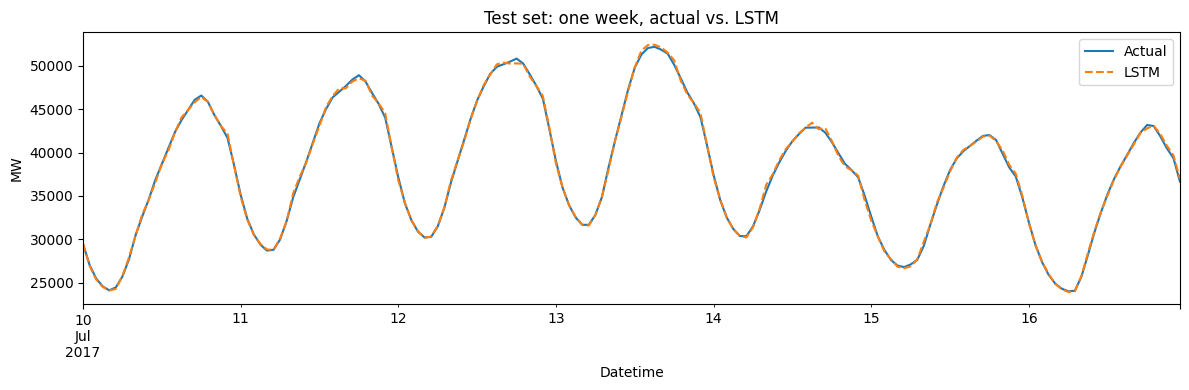

In [4]:
def metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"MAE": round(mae, 1), "RMSE": round(rmse, 1), "MAPE %": round(mape, 2)}

pred = predict(test_ds).numpy() * sd + mu          # MW'a geri çevir
actual = y[split_t:]
test_index = df.index[split_t:]

results = {
    "Naive (same hour yesterday)":  {"MAE": 2184.3, "RMSE": 3009.0, "MAPE %": 6.93},
    "Naive (same hour last week)":  {"MAE": 3391.9, "RMSE": 4670.3, "MAPE %": 10.56},
    "Naive (1 hour ago)":           {"MAE": 1070.0, "RMSE": 1373.8, "MAPE %": 3.48},
    "Linear Regression":            {"MAE": 977.0,  "RMSE": 1254.2, "MAPE %": 3.15},
    "Random Forest":                {"MAE": 336.3,  "RMSE": 462.7,  "MAPE %": 1.07},
    "LSTM":                         metrics(actual, pred),
}
display(pd.DataFrame(results).T)

week = slice("2017-07-10", "2017-07-16")
s_act = pd.Series(actual, index=test_index); s_pred = pd.Series(pred, index=test_index)
plt.figure(figsize=(12, 4))
s_act.loc[week].plot(label="Actual"); s_pred.loc[week].plot(label="LSTM", linestyle="--")
plt.ylabel("MW"); plt.title("Test set: one week, actual vs. LSTM"); plt.legend(); plt.tight_layout(); plt.show()